# Import library

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, GRU, Dense, Dropout,LSTM
from tensorflow.keras.utils import to_categorical
import numpy as np

2026-08-17 15:29:23.034770: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1786980563.257096      18 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1786980563.319006      18 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


# Load Dataset

In [2]:
data = pd.read_csv("/kaggle/input/erp-datasett/erp_reviews_with_sentiment.csv")

# Data Analysis (EDA) 

In [3]:
len(data)

2950

In [4]:
data.head(10)

,Review_Answer,Sentiment_Label
0,All modules are easily accessible within the m...,Positive
1,It would be nice if you could somehow easily s...,Neutral
2,Having visibility into all orders and all the ...,Positive
3,"The learning curve was steep, like with most E...",Positive
4,XoroERP is our one stop shop for all our opera...,Positive
5,"The implementation phase was a bit long, but o...",Positive
6,Some learning curve shifting from QBO to Xoro,Neutral
7,"Helping us tie together our entire operation, ...",Positive
8,"There was a notable learning curve, and we wen...",Negative
9,Assisting us in integrating our entire operati...,Positive


In [5]:
import os
import re
import gc
import math
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter
from typing import List, Tuple

# Optional (usually available on Kaggle):
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split

# NLTK (download once; harmless if already present)
import nltk
nltk.download('punkt', quiet=True)
nltk.download('stopwords', quiet=True)
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

[nltk_data] Error loading punkt: HTTP Error 503: first byte timeout
[nltk_data] Error loading stopwords: HTTP Error 503: first byte
[nltk_data]     timeout



# 1) Load & basic overview


In [6]:

CSV_PATH = "/kaggle/input/erp-datasett/erp_reviews_with_sentiment.csv"
assert os.path.exists(CSV_PATH), f"File not found: {CSV_PATH}"

df = pd.read_csv(CSV_PATH)
print("Shape:", df.shape, "\n")
print("Columns:", list(df.columns), "\n")

print("Data types:")
print(df.dtypes, "\n")

print("Preview:")
display(df.head())

Shape: (2950, 2) 

Columns: ['Review_Answer', 'Sentiment_Label'] 

Data types:
Review_Answer      object
Sentiment_Label    object
dtype: object 

Preview:


,Review_Answer,Sentiment_Label
0,All modules are easily accessible within the m...,Positive
1,It would be nice if you could somehow easily s...,Neutral
2,Having visibility into all orders and all the ...,Positive
3,"The learning curve was steep, like with most E...",Positive
4,XoroERP is our one stop shop for all our opera...,Positive


# 3) Missing values & dupes

In [7]:
text_col_candidates = [c for c in df.columns if c.lower() in ["review_text", "review", "text", "content", "body"]]
label_col_candidates = [c for c in df.columns if c.lower() in ["sentiment", "label", "target", "polarity", "y"]]

review_col = text_col_candidates[0] if text_col_candidates else None
label_col  = label_col_candidates[0] if label_col_candidates else None

if review_col is None:
    # Use the first object/string-like column as review text
    obj_cols = [c for c in df.columns if df[c].dtype == "object"]
    review_col = obj_cols[0] if obj_cols else df.columns[0]

if label_col is None:
    # Heuristic: pick a non-text column with low cardinality as label
    candidate = None
    for c in df.columns:
        if c == review_col:
            continue
        uniq = df[c].nunique(dropna=True)
        if uniq > 0 and uniq <= max(10, int(0.01 * len(df))):
            candidate = c
            break
    label_col = candidate if candidate else df.columns[1]

print(f"Using review column: '{review_col}'")
print(f"Using label  column: '{label_col}'\n")


Using review column: 'Review_Answer'
Using label  column: 'Sentiment_Label'



In [8]:
print("Missing values per column:")
print(df.isna().sum().sort_values(ascending=False), "\n")

# Drop completely empty rows in key fields for EDA view (don’t overwrite original df)
df_eda = df.copy()
df_eda = df_eda.dropna(subset=[review_col, label_col])
df_eda[review_col] = df_eda[review_col].astype(str).str.strip()

# Remove literal duplicates of (text,label) pairs for clean stats
dupe_count = df_eda.duplicated(subset=[review_col, label_col]).sum()
print(f"Exact duplicate (text,label) rows: {dupe_count}\n")
df_eda = df_eda.drop_duplicates(subset=[review_col, label_col])

Missing values per column:
Review_Answer      1
Sentiment_Label    0
dtype: int64 

Exact duplicate (text,label) rows: 657



# 4) Class distribution

Class distribution:
Sentiment_Label
Positive    1611
Neutral      424
Negative     257
Name: count, dtype: int64 



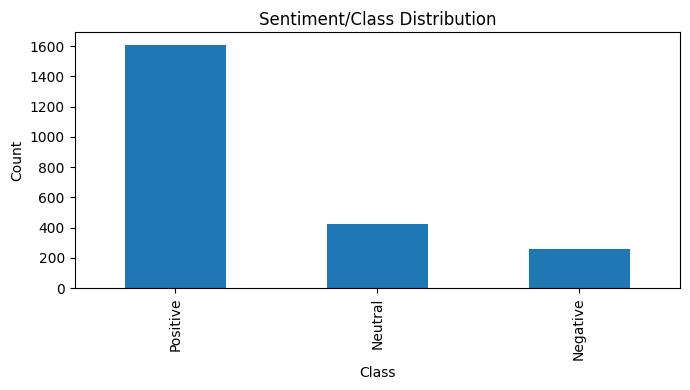

Class proportions:
Sentiment_Label
Negative    11.21%
Neutral     18.50%
Positive    70.29%
Name: count, dtype: object 



In [9]:
print("Class distribution:")
class_counts = df_eda[label_col].value_counts(dropna=False)
print(class_counts, "\n")

plt.figure(figsize=(7,4))
class_counts.plot(kind="bar")
plt.title("Sentiment/Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

# If imbalanced, show proportions as well
class_props = (class_counts / class_counts.sum()).sort_index()
print("Class proportions:")
print(class_props.map(lambda x: f"{x:.2%}"), "\n")


# 5) Text length features


Basic text length summary (chars):
count    2292.000000
mean      182.270070
std       158.250951
min         2.000000
10%        50.000000
25%        74.750000
50%       137.000000
75%       239.000000
90%       370.000000
95%       476.000000
99%       752.810000
max      2259.000000
Name: char_len, dtype: float64 

Basic text length summary (words):
count    2292.000000
mean       31.192408
std        27.343796
min         1.000000
10%         8.000000
25%        13.000000
50%        24.000000
75%        40.000000
90%        63.000000
95%        80.000000
99%       133.000000
max       403.000000
Name: word_len, dtype: float64 



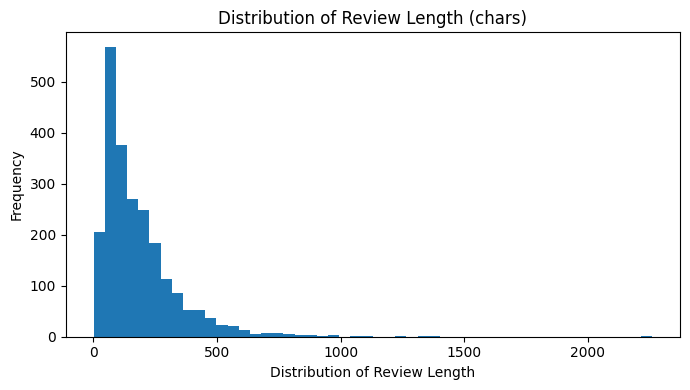

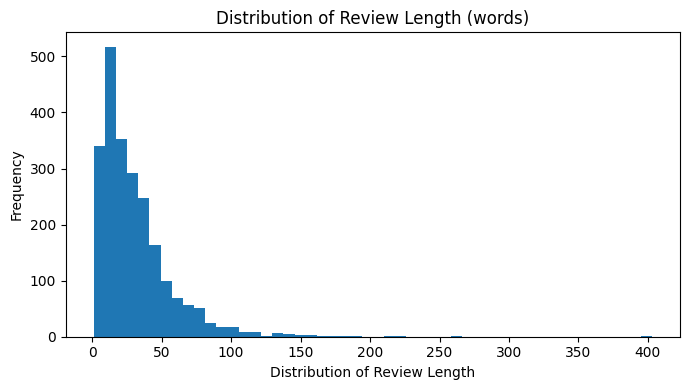

Word length by class (count/mean/median/std):
                  count       mean  median        std
Sentiment_Label                                     
Positive          1611  31.795158    24.0  27.695442
Neutral            424  29.285377    23.0  22.868856
Negative           257  30.560311    20.0  31.533670 



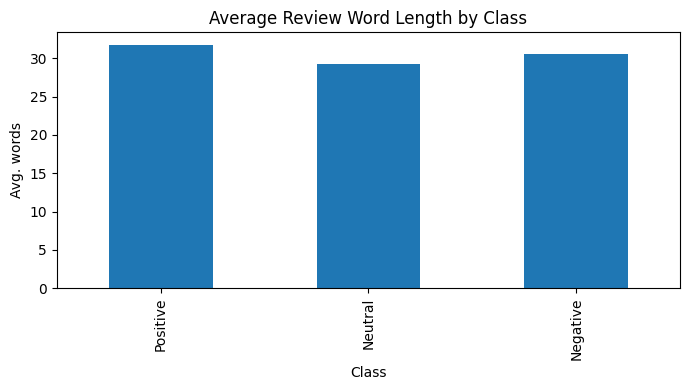

In [10]:
def safe_word_count(s: str) -> int:
    # Tokenize lightly; keep it fast
    return len([w for w in re.findall(r"\b\w+\b", s.lower())])

df_eda["char_len"] = df_eda[review_col].str.len()
df_eda["word_len"] = df_eda[review_col].apply(safe_word_count)

print("Basic text length summary (chars):")
print(df_eda["char_len"].describe(percentiles=[.1,.25,.5,.75,.9,.95,.99]), "\n")

print("Basic text length summary (words):")
print(df_eda["word_len"].describe(percentiles=[.1,.25,.5,.75,.9,.95,.99]), "\n")

# Histograms for lengths
def plot_hist(series, title, bins=50):
    plt.figure(figsize=(7,4))
    plt.hist(series.dropna(), bins=bins, density=False)
    plt.title(title)
    plt.xlabel(title.split(" (")[0])
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

plot_hist(df_eda["char_len"], "Distribution of Review Length (chars)")
plot_hist(df_eda["word_len"], "Distribution of Review Length (words)")

# Length by class (mean & median)
group_len = df_eda.groupby(label_col)["word_len"].agg(['count','mean','median','std']).sort_values("count", ascending=False)
print("Word length by class (count/mean/median/std):\n", group_len, "\n")

# Bar chart of average word length per class
plt.figure(figsize=(7,4))
group_len["mean"].plot(kind="bar")
plt.title("Average Review Word Length by Class")
plt.xlabel("Class")
plt.ylabel("Avg. words")
plt.tight_layout()
plt.show()

# 6) Label–text sanity checks

In [11]:
# -------------------------

# -------------------------
# Quick heuristic “leakage” check: very long texts only in one class
lens_by_class = df_eda.groupby(label_col)["word_len"].describe()[["mean","std","min","25%","50%","75%","max"]]
print("Word length distribution by class:\n")
print(lens_by_class, "\n")

# Show a few very long and very short reviews for manual inspection (safe preview)
print("Shortest reviews (inspect labeling correctness):")
display(df_eda.sort_values("word_len").head(5)[[label_col, review_col, "word_len"]])

print("Longest reviews (inspect labeling correctness):")
display(df_eda.sort_values("word_len", ascending=False).head(5)[[label_col, review_col, "word_len"]])


Word length distribution by class:

                      mean        std  min   25%   50%   75%    max
Sentiment_Label                                                    
Negative         30.560311  31.533670  1.0  11.0  20.0  39.0  261.0
Neutral          29.285377  22.868856  2.0  13.0  23.0  37.0  173.0
Positive         31.795158  27.695442  1.0  13.0  24.0  41.0  403.0 

Shortest reviews (inspect labeling correctness):


,Sentiment_Label,Review_Answer,word_len
2150,Positive,Hr,1
1644,Positive,Auditing,1
1687,Negative,nothing,1
2356,Negative,NO COMMENT,2
2202,Negative,Leave usage,2


Longest reviews (inspect labeling correctness):


,Sentiment_Label,Review_Answer,word_len
27,Positive,Moving to a new ERP system in this day and age...,403
2069,Negative,"Acumatica is built with very large, multinatio...",261
1758,Negative,We were promised that the software could do wh...,220
838,Positive,The smooth automation of Rippling is one of th...,212
492,Positive,There is really efficient design in just even ...,193


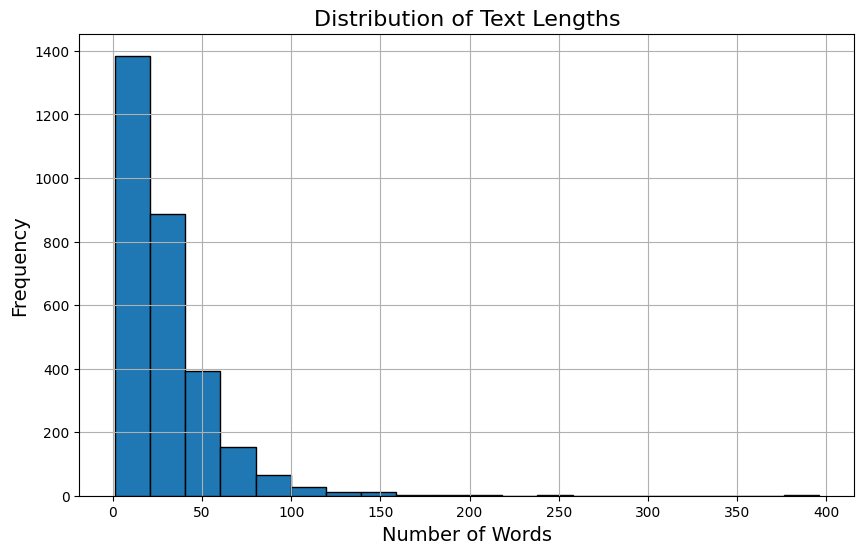

In [12]:
import pandas as pd
import matplotlib.pyplot as plt



# Calculate the length of each statement in the 'text' column
data['length'] = data['Review_Answer'].apply(lambda x: len(str(x).split()))

# Plot the distribution of text lengths
plt.figure(figsize=(10, 6))
plt.hist(data['length'], bins=20, edgecolor='black')
plt.title('Distribution of Text Lengths', fontsize=16)
plt.xlabel('Number of Words', fontsize=14)
plt.ylabel('Frequency', fontsize=14)
plt.grid(True)
plt.show()


In [13]:
data

,Review_Answer,Sentiment_Label,length
0,All modules are easily accessible within the m...,Positive,73
1,It would be nice if you could somehow easily s...,Neutral,21
2,Having visibility into all orders and all the ...,Positive,66
3,"The learning curve was steep, like with most E...",Positive,26
4,XoroERP is our one stop shop for all our opera...,Positive,64
...,...,...,...
2945,I wish there was a way for the product to link...,Neutral,21
2946,"People management, training, compensation, pay...",Positive,8
2947,Great for managing employee info. I find that ...,Positive,25
2948,Permissions and what it limits you to sometime...,Neutral,23


In [14]:
from nltk.tokenize import word_tokenize

# Combine all cleaned statements into one text
all_clean_text = ' '.join(data['Review_Answer'].astype(str))
# Tokenize and find unique words
unique_words = set(word_tokenize(all_clean_text))

# Count the number of unique words
unique_word_count = len(unique_words)

print(f"Total unique words: {unique_word_count}")


Total unique words: 6376


# Data Preprocessing

In [15]:
# ==========================
# Preprocessing of ERP Reviews
# ==========================
import pandas as pd
import re
import string
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Download required NLTK resources (only once)
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('wordnet')
nltk.download('omw-1.4')

# Load your dataset
data = pd.read_csv("/kaggle/input/erp-datasett/erp_reviews_with_sentiment.csv")

# -----------------------------
# 1. Remove low-length reviews
# -----------------------------
# Define a minimum word length threshold (e.g., 5 words)
data['length'] = data['Review_Answer'].astype(str).apply(lambda x: len(x.split()))
data = data[data['length'] >= 5]

print("After removing short reviews:", data.shape)

# -----------------------------
# 2. Clean punctuation and digits
# -----------------------------
def remove_punct(text):
    # remove punctuation and digits, keep only letters and whitespace
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    return text

data['clean_text'] = data['Review_Answer'].astype(str).apply(remove_punct)

# -----------------------------
# 3. Normalize and lowercase
# -----------------------------
data['clean_text'] = data['clean_text'].str.lower()
# normalize whitespace
data['clean_text'] = data['clean_text'].str.replace(r'\s+', ' ', regex=True).str.strip()

# -----------------------------
# 4. Tokenization & Stopword removal
# -----------------------------
stop_words = set(stopwords.words('english'))

def remove_stopwords(text):
    tokens = nltk.word_tokenize(text)
    filtered = [w for w in tokens if w not in stop_words]
    return filtered

data['tokens'] = data['clean_text'].apply(remove_stopwords)

# -----------------------------
# 5. Lemmatization
# -----------------------------
lemmatizer = WordNetLemmatizer()

def lemmatize_tokens(tokens):
    return [lemmatizer.lemmatize(t) for t in tokens]

data['lemmas'] = data['tokens'].apply(lemmatize_tokens)

# -----------------------------
# 6. Join back into clean text
# -----------------------------
data['final_text'] = data['lemmas'].apply(lambda x: " ".join(x))

# -----------------------------
# Final preview
# -----------------------------
print(data[['Review_Answer', 'Sentiment_Label', 'final_text']].head(10))

# Save preprocessed dataset
data[['final_text', 'Sentiment_Label']].to_csv("/kaggle/working/erp_reviews_preprocessed.csv", index=False)
print("Preprocessed dataset saved!")


[nltk_data] Error loading stopwords: HTTP Error 429: Too Many Requests
[nltk_data] Error loading punkt: HTTP Error 429: Too Many Requests
[nltk_data] Error loading wordnet: HTTP Error 429: Too Many Requests
[nltk_data] Error loading omw-1.4: HTTP Error 429: Too Many Requests


After removing short reviews: (2872, 3)
                                       Review_Answer Sentiment_Label  \
0  All modules are easily accessible within the m...        Positive   
1  It would be nice if you could somehow easily s...         Neutral   
2  Having visibility into all orders and all the ...        Positive   
3  The learning curve was steep, like with most E...        Positive   
4  XoroERP is our one stop shop for all our opera...        Positive   
5  The implementation phase was a bit long, but o...        Positive   
6      Some learning curve shifting from QBO to Xoro         Neutral   
7  Helping us tie together our entire operation, ...        Positive   
8  There was a notable learning curve, and we wen...        Negative   
9  Assisting us in integrating our entire operati...        Positive   

                                          final_text  
0  module easily accessible within menu using dro...  
1  would nice could somehow easily switch user wi...  
2 

In [16]:
data = pd.read_csv("/kaggle/input/erp-datasett/erp_reviews_with_sentiment.csv")


In [17]:
data

,Review_Answer,Sentiment_Label
0,All modules are easily accessible within the m...,Positive
1,It would be nice if you could somehow easily s...,Neutral
2,Having visibility into all orders and all the ...,Positive
3,"The learning curve was steep, like with most E...",Positive
4,XoroERP is our one stop shop for all our opera...,Positive
...,...,...
2945,I wish there was a way for the product to link...,Neutral
2946,"People management, training, compensation, pay...",Positive
2947,Great for managing employee info. I find that ...,Positive
2948,Permissions and what it limits you to sometime...,Neutral


In [18]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder


# Initialize LabelEncoder
label_encoder = LabelEncoder()

# Fit and transform the 'category' column
data['category_encoded'] = label_encoder.fit_transform(data['Sentiment_Label'])

# View the mapping of labels to encoded values
label_mapping = dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))
print("Label Mapping:", label_mapping)

# Now you have the category labels encoded in the 'category_encoded' column
texts = data['Review_Answer'].astype(str).values  # Text data
labels = data['category_encoded'].values  # Encoded labels

# Split the dataset into training and testing sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(texts, labels, test_size=0.2, random_state=42)


Label Mapping: {'Negative': 0, 'Neutral': 1, 'Positive': 2}


# GRU 

In [19]:

# Tokenize the text
max_vocab_size = 6376  # Define maximum vocabulary size
max_sequence_length = 100  # Define maximum sequence length for padding

tokenizer = Tokenizer(num_words=max_vocab_size)
tokenizer.fit_on_texts(X_train)
X_train_sequences = tokenizer.texts_to_sequences(X_train)
X_test_sequences = tokenizer.texts_to_sequences(X_test)

# Pad sequences to ensure equal length
X_train_padded = pad_sequences(X_train_sequences, maxlen=max_sequence_length)
X_test_padded = pad_sequences(X_test_sequences, maxlen=max_sequence_length)

# Convert labels to categorical format
num_classes = len(np.unique(labels))
y_train_categorical = to_categorical(y_train, num_classes=num_classes)
y_test_categorical = to_categorical(y_test, num_classes=num_classes)


In [20]:
# Build the GRU model
embedding_dim = 4  # Dimension of embedding vector
model = Sequential()
model.add(Embedding(input_dim=max_vocab_size, output_dim=embedding_dim, input_length=max_sequence_length))
model.add(GRU(128, return_sequences=True))
model.add(Dropout(0.5))
model.add(GRU(64))
model.add(Dropout(0.5))
model.add(Dense(num_classes, activation='softmax'))
# Check the distribution of labels
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Calculate class weights
class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weights_dict = dict(enumerate(class_weights))


# Compile the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Train the model
batch_size = 64
epochs = 10  # Adjust based on training needs
history = model.fit(X_train_padded, y_train_categorical, batch_size=batch_size, epochs=epochs, validation_data=(X_test_padded, y_test_categorical), class_weight=class_weights_dict)


Epoch 1/10


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(
I0000 00:00:1786981047.106380      18 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15511 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0
I0000 00:00:1786981052.505907      59 cuda_dnn.cc:529] Loaded cuDNN version 90300


37/37 ━━━━━━━━━━━━━━━━━━━━ 7s 28ms/step - accuracy: 0.3641 - loss: 1.0927 - val_accuracy: 0.3136 - val_loss: 1.0952
Epoch 2/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.2393 - loss: 1.0947 - val_accuracy: 0.6119 - val_loss: 1.0245
Epoch 3/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.6140 - loss: 1.0042 - val_accuracy: 0.7525 - val_loss: 0.7014
Epoch 4/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.7586 - loss: 0.7876 - val_accuracy: 0.7763 - val_loss: 0.5141
Epoch 5/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.7497 - loss: 0.7273 - val_accuracy: 0.6068 - val_loss: 0.9943
Epoch 6/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.7620 - loss: 0.7096 - val_accuracy: 0.7441 - val_loss: 0.6302
Epoch 7/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.8277 - loss: 0.5761 - val_accuracy: 0.7441 - val_loss: 0.6757
Epoch 8/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.8814 - loss: 0.4625 - val_accuracy: 0.7966 - val_loss: 0.

In [21]:
# Save the entire model to a file
model.save('gru_model.h5')  # You can change the filename as needed

print("Model has been saved successfully.")


Model has been saved successfully.


In [22]:
# Evaluate the model
loss, accuracy = model.evaluate(X_test_padded, y_test_categorical)
print(f'Test Accuracy: {accuracy * 100:.2f}%')



19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8245 - loss: 0.5225
Test Accuracy: 81.86%


19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step


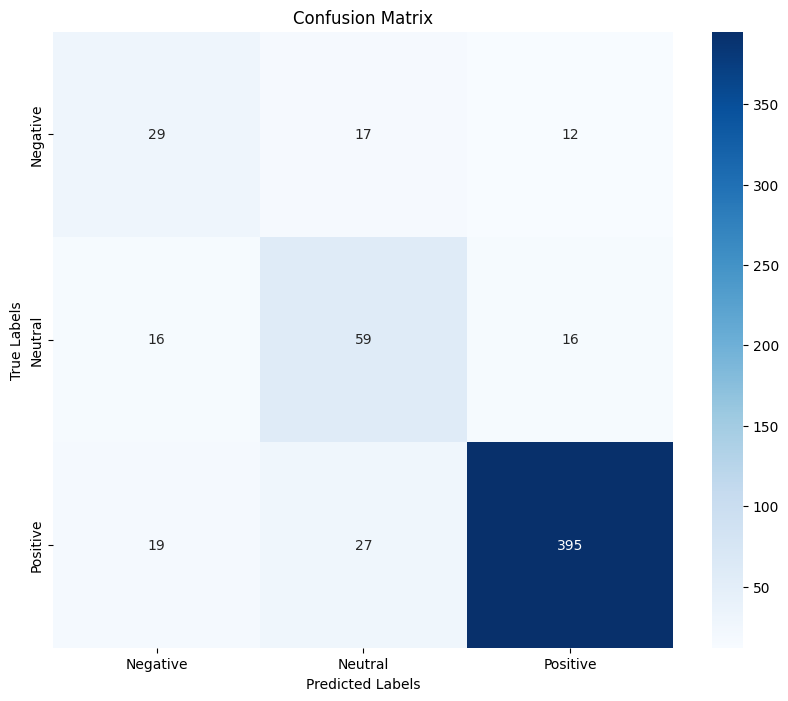

              precision    recall  f1-score   support

    Negative       0.45      0.50      0.48        58
     Neutral       0.57      0.65      0.61        91
    Positive       0.93      0.90      0.91       441

    accuracy                           0.82       590
   macro avg       0.65      0.68      0.67       590
weighted avg       0.83      0.82      0.82       590



In [23]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Predict the categories for the test set
y_pred_probs = model.predict(X_test_padded)  # Predict probabilities for each class
y_pred = np.argmax(y_pred_probs, axis=1)     # Convert probabilities to class labels

# Convert one-hot encoded test labels back to single integer labels
y_test_labels = np.argmax(y_test_categorical, axis=1)

# Generate the confusion matrix
conf_matrix = confusion_matrix(y_test_labels, y_pred)

# Plot the confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

# Print classification report for precision, recall, f1-score
print(classification_report(y_test_labels, y_pred, target_names=label_encoder.classes_))


In [24]:
import numpy as np

# Function to preprocess and predict the category of a new sentence
def predict_category(text):
    # Tokenize and pad the input sentence
    sequence = tokenizer.texts_to_sequences([text])
    padded_sequence = pad_sequences(sequence, maxlen=max_sequence_length)
    
    # Get prediction from the model
    prediction = model.predict(padded_sequence)
    predicted_label = label_encoder.inverse_transform([np.argmax(prediction)])[0]
    
    return predicted_label



example_sentences = [
   "She stared out of the rain-soaked window, her heart aching as memories of better days consumed her.", 
    "His voice thundered through the room as he slammed the table, anger boiling over after the betrayal.", 
    "Her hands trembled as she walked through the dark forest, every rustle of leaves intensifying her fear.", 
    "When they opened the door, they were shocked to find a beautiful surprise party waiting for them.", 
        "The little girl danced around the garden, her cheerful laughter ringing out as she chased colorful butterflies.", 
    "They walked hand in hand along the beach, their footprints tracing a journey of shared dreams and promises.", 
]

print("This is GRU model : ")

# Predict categories for each example sentence
for i, sentence in enumerate(example_sentences, 1):
    predicted_category = predict_category(sentence)
    print(f"Sentence {i}: {sentence}")
    print(f"Predicted Category: {predicted_category}\n")


This is GRU model : 
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
Sentence 1: She stared out of the rain-soaked window, her heart aching as memories of better days consumed her.
Predicted Category: Negative

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
Sentence 2: His voice thundered through the room as he slammed the table, anger boiling over after the betrayal.
Predicted Category: Negative

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
Sentence 3: Her hands trembled as she walked through the dark forest, every rustle of leaves intensifying her fear.
Predicted Category: Positive

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
Sentence 4: When they opened the door, they were shocked to find a beautiful surprise party waiting for them.
Predicted Category: Neutral

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
Sentence 5: The little girl danced around the garden, her cheerful laughter ringing out as she chased colorful butterflies.
Predicted Category: Positive

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
Sentence 6: They walked han

# LSTM model 

In [25]:
# Build the GRU model
embedding_dim = 8  # Dimension of embedding vector
model = Sequential()
model.add(Embedding(input_dim=max_vocab_size, output_dim=embedding_dim, input_length=max_sequence_length))
model.add(LSTM(128, return_sequences=True))
model.add(Dropout(0.5))
model.add(LSTM(64))
model.add(Dropout(0.5))
model.add(Dense(num_classes, activation='softmax'))
# Check the distribution of labels
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Calculate class weights
class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weights_dict = dict(enumerate(class_weights))


# Compile the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Train the model
batch_size = 64
epochs = 10 # Adjust based on training needs
history = model.fit(X_train_padded, y_train_categorical, batch_size=batch_size, epochs=epochs, validation_data=(X_test_padded, y_test_categorical), class_weight=class_weights_dict)


Epoch 1/10


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


37/37 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - accuracy: 0.4137 - loss: 1.1046 - val_accuracy: 0.7424 - val_loss: 1.0712
Epoch 2/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.5352 - loss: 1.0739 - val_accuracy: 0.4983 - val_loss: 1.0779
Epoch 3/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.6167 - loss: 0.9094 - val_accuracy: 0.7203 - val_loss: 0.6507
Epoch 4/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.7318 - loss: 0.7032 - val_accuracy: 0.7136 - val_loss: 0.7476
Epoch 5/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.8045 - loss: 0.4987 - val_accuracy: 0.7475 - val_loss: 0.6376
Epoch 6/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9009 - loss: 0.3013 - val_accuracy: 0.8475 - val_loss: 0.4349
Epoch 7/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.9312 - loss: 0.1981 - val_accuracy: 0.8254 - val_loss: 0.5555
Epoch 8/10
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9523 - loss: 0.1274 - val_accuracy: 0.8373 - val_loss: 0.

In [26]:
# Save the entire model to a file
model.save('LSTM_model.h5')  # You can change the filename as needed

print("Model has been saved successfully.")


Model has been saved successfully.


In [27]:
# Evaluate the model
loss, accuracy = model.evaluate(X_test_padded, y_test_categorical)
print(f'Test Accuracy: {accuracy * 100:.2f}%')



19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8725 - loss: 0.5919
Test Accuracy: 86.78%


19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step


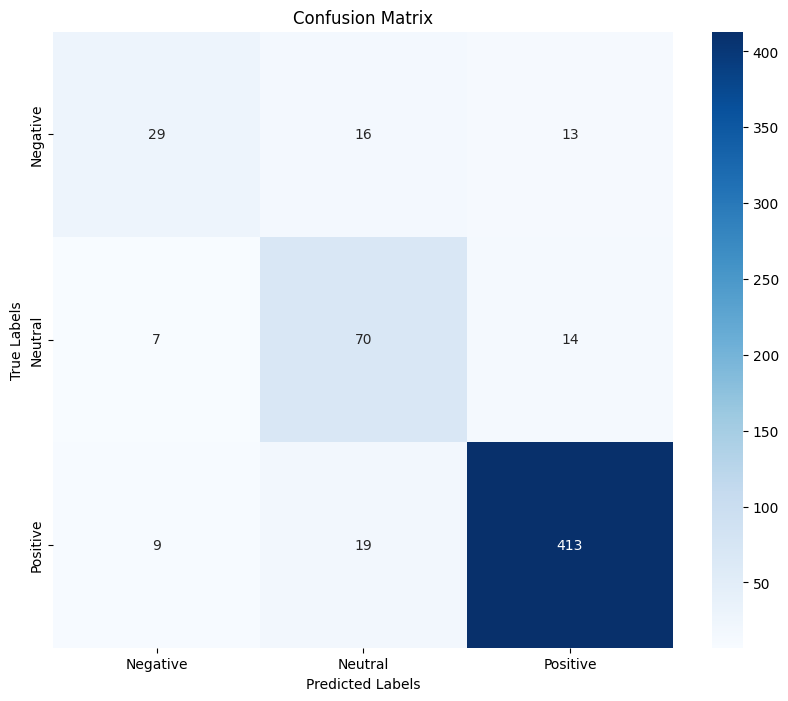

              precision    recall  f1-score   support

    Negative       0.64      0.50      0.56        58
     Neutral       0.67      0.77      0.71        91
    Positive       0.94      0.94      0.94       441

    accuracy                           0.87       590
   macro avg       0.75      0.74      0.74       590
weighted avg       0.87      0.87      0.87       590



In [28]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Predict the categories for the test set
y_pred_probs = model.predict(X_test_padded)  # Predict probabilities for each class
y_pred = np.argmax(y_pred_probs, axis=1)     # Convert probabilities to class labels

# Convert one-hot encoded test labels back to single integer labels
y_test_labels = np.argmax(y_test_categorical, axis=1)

# Generate the confusion matrix
conf_matrix = confusion_matrix(y_test_labels, y_pred)

# Plot the confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

# Print classification report for precision, recall, f1-score
print(classification_report(y_test_labels, y_pred, target_names=label_encoder.classes_))


# Roberta model 

In [29]:
!pip install transformers

In [30]:
import torch
from transformers import RobertaTokenizer, RobertaForSequenceClassification
# from transformers import AdamW
from torch.optim import AdamW

# Load the tokenizer and model
tokenizer = RobertaTokenizer.from_pretrained("roberta-base")
model = RobertaForSequenceClassification.from_pretrained("roberta-base", num_labels=len(label_mapping))

# Tokenize the data
def encode_texts(texts, tokenizer, max_length=128):
    return tokenizer(list(texts), padding=True, truncation=True, max_length=max_length, return_tensors="pt")

# Encode the training and testing data
train_encodings = encode_texts(X_train, tokenizer)
test_encodings = encode_texts(X_test, tokenizer)

# Convert labels to tensors
y_train_tensor = torch.tensor(y_train)
y_test_tensor = torch.tensor(y_test)

# Create DataLoader
from torch.utils.data import DataLoader, TensorDataset

train_dataset = TensorDataset(train_encodings['input_ids'], train_encodings['attention_mask'], y_train_tensor)
test_dataset = TensorDataset(test_encodings['input_ids'], test_encodings['attention_mask'], y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=16)

# Define optimizer
optimizer = AdamW(model.parameters(), lr=5e-5)

# Training loop
from torch.nn import CrossEntropyLoss
from torch.utils.data import DataLoader
from tqdm import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

epochs = 5
loss_fn = CrossEntropyLoss()

for epoch in range(epochs):
    model.train()
    total_loss = 0
    for batch in tqdm(train_loader):
        optimizer.zero_grad()
        
        input_ids = batch[0].to(device)
        attention_mask = batch[1].to(device)
        labels = batch[2].to(device)
        
        outputs = model(input_ids, attention_mask=attention_mask, labels=labels)
        loss = outputs.loss
        total_loss += loss.item()
        
        loss.backward()
        optimizer.step()
    
    print(f"Epoch {epoch + 1}, Loss: {total_loss / len(train_loader)}")

# Evaluate the model
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for batch in test_loader:
        input_ids = batch[0].to(device)
        attention_mask = batch[1].to(device)
        labels = batch[2].to(device)
        
        outputs = model(input_ids, attention_mask=attention_mask)
        predictions = torch.argmax(outputs.logits, dim=1)
        
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

print(f"Test Accuracy: {correct / total:.2f}")

# Save the model
model.save_pretrained("roberta_emotion_model")
tokenizer.save_pretrained("roberta_emotion_model")
print("Model saved successfully.")


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

...

Epoch 3, Loss: 0.3153460188391241


100%|██████████| 148/148 [00:29<00:00,  4.94it/s]


Epoch 4, Loss: 0.2303822911784959


100%|██████████| 148/148 [00:30<00:00,  4.93it/s]


Epoch 5, Loss: 0.1611822889850324
Test Accuracy: 0.92
Model saved successfully.


In [31]:
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns


In [32]:
# Generate predictions on the test set
model.eval()
predictions = []
true_labels = []

with torch.no_grad():
    for batch in test_loader:
        input_ids = batch[0].to(device)
        attention_mask = batch[1].to(device)
        labels = batch[2].to(device)
        
        outputs = model(input_ids, attention_mask=attention_mask)
        preds = torch.argmax(outputs.logits, dim=1)
        
        predictions.extend(preds.cpu().numpy())
        true_labels.extend(labels.cpu().numpy())


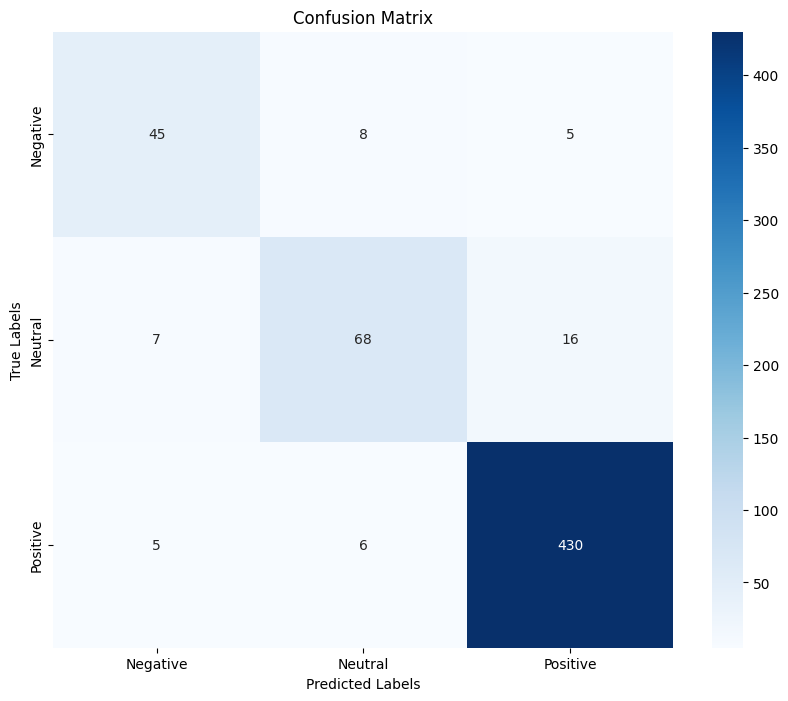

In [33]:
# Create the confusion matrix
cm = confusion_matrix(true_labels, predictions)

# Plot the confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=label_mapping.keys(), yticklabels=label_mapping.keys())
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.title("Confusion Matrix")
plt.show()


In [34]:
print("Classification Report:\n")
print(classification_report(true_labels, predictions, target_names=label_mapping.keys()))


Classification Report:

              precision    recall  f1-score   support

    Negative       0.79      0.78      0.78        58
     Neutral       0.83      0.75      0.79        91
    Positive       0.95      0.98      0.96       441

    accuracy                           0.92       590
   macro avg       0.86      0.83      0.84       590
weighted avg       0.92      0.92      0.92       590



In [35]:
import torch
from transformers import RobertaTokenizer, RobertaForSequenceClassification

# Load tokenizer and fine-tuned model
model_path = "/kaggle/working/roberta_emotion_model"   # change if you saved in another directory
tokenizer = RobertaTokenizer.from_pretrained(model_path)
model = RobertaForSequenceClassification.from_pretrained(model_path)

# Set device (GPU if available, otherwise CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)  
model.eval()

# Example sentences
example_sentences = [
   "She stared out of the rain-soaked window, her heart aching as memories of better days consumed her.", 
   "His voice thundered through the room as he slammed the table, anger boiling over after the betrayal.", 
   "Her hands trembled as she walked through the dark forest, every rustle of leaves intensifying her fear.", 
   "When they opened the door, they were shocked to find a beautiful surprise party waiting for them.", 
   "The little girl danced around the garden, her cheerful laughter ringing out as she chased colorful butterflies.", 
   "They walked hand in hand along the beach, their footprints tracing a journey of shared dreams and promises.", 
]

# Tokenize and move tensors to the same device as the model
inputs = tokenizer(example_sentences, padding=True, truncation=True, return_tensors="pt").to(device)

# Make predictions
with torch.no_grad():
    outputs = model(**inputs)
    probs = torch.nn.functional.softmax(outputs.logits, dim=-1)
    predictions = torch.argmax(probs, dim=1)

# Map predictions to labels
id2label = {0: "Negative", 1: "Neutral", 2: "Positive"}  # adjust if your label order differs
for sent, pred, prob in zip(example_sentences, predictions, probs):
    print(f"Sentence: {sent}")
    print(f"Predicted Sentiment: {id2label[pred.item()]} (Confidence: {prob[pred].item():.2f})\n")


Sentence: She stared out of the rain-soaked window, her heart aching as memories of better days consumed her.
Predicted Sentiment: Negative (Confidence: 0.80)

Sentence: His voice thundered through the room as he slammed the table, anger boiling over after the betrayal.
Predicted Sentiment: Negative (Confidence: 0.87)

Sentence: Her hands trembled as she walked through the dark forest, every rustle of leaves intensifying her fear.
Predicted Sentiment: Negative (Confidence: 0.82)

Sentence: When they opened the door, they were shocked to find a beautiful surprise party waiting for them.
Predicted Sentiment: Negative (Confidence: 0.57)

Sentence: The little girl danced around the garden, her cheerful laughter ringing out as she chased colorful butterflies.
Predicted Sentiment: Positive (Confidence: 0.84)

Sentence: They walked hand in hand along the beach, their footprints tracing a journey of shared dreams and promises.
Predicted Sentiment: Negative (Confidence: 0.76)



# Machine learning model 

In [36]:
data['category_encoded'].value_counts()

category_encoded
2    2100
1     534
0     316
Name: count, dtype: int64

Training and evaluating: Logistic Regression

Classification Report for Logistic Regression:

              precision    recall  f1-score   support

    Negative       1.00      0.21      0.34        58
     Neutral       0.73      0.56      0.63        91
    Positive       0.85      0.98      0.91       441

    accuracy                           0.84       590
   macro avg       0.86      0.58      0.63       590
weighted avg       0.85      0.84      0.81       590



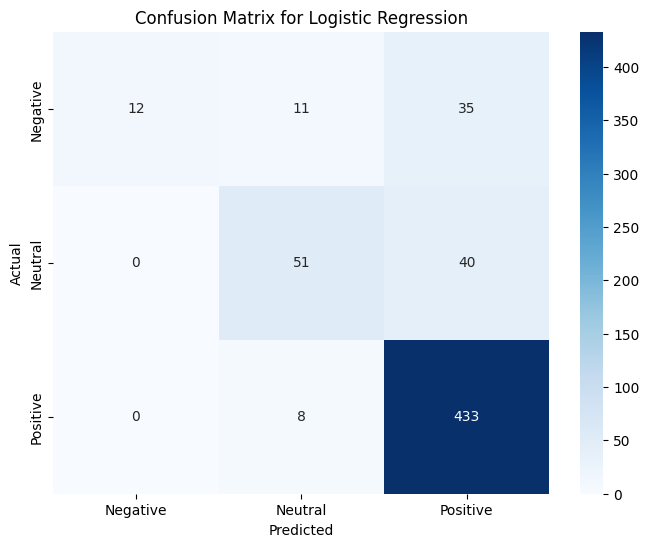

Logistic Regression saved as logistic_regression_model.pkl
Training and evaluating: Random Forest

Classification Report for Random Forest:

              precision    recall  f1-score   support

    Negative       0.95      0.36      0.53        58
     Neutral       0.85      0.70      0.77        91
    Positive       0.89      0.99      0.94       441

    accuracy                           0.88       590
   macro avg       0.90      0.69      0.74       590
weighted avg       0.89      0.88      0.87       590



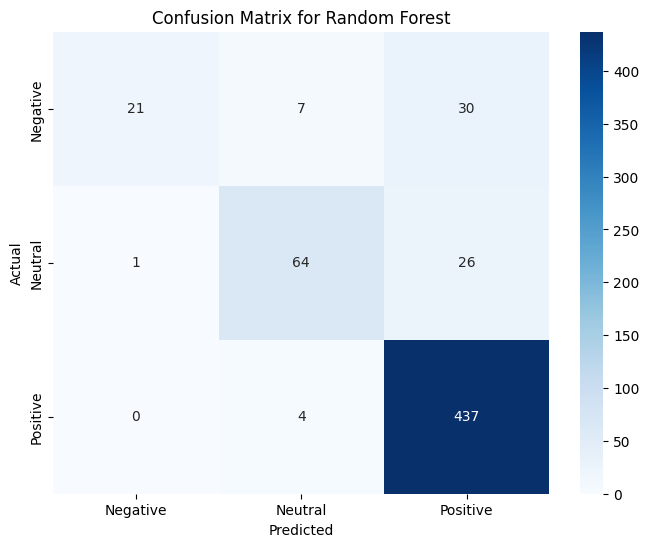

Random Forest saved as random_forest_model.pkl


In [37]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier



# Convert text data into TF-IDF features
vectorizer = TfidfVectorizer(max_features=5000)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# Define models
models = {
    "Logistic Regression": LogisticRegression(),
    "Random Forest": RandomForestClassifier(),

}

# Train, predict, evaluate, and save each model
for model_name, model in models.items():
    print(f"Training and evaluating: {model_name}")
    model.fit(X_train_tfidf, y_train)
    y_pred = model.predict(X_test_tfidf)
    
    # Print classification report
    print(f"\nClassification Report for {model_name}:\n")
    print(classification_report(y_test, y_pred, target_names=label_mapping.keys()))
    
    # Generate confusion matrix
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_mapping.keys(), yticklabels=label_mapping.keys())
    plt.title(f"Confusion Matrix for {model_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()
    
    # Save the trained model
    model_path = f"{model_name.replace(' ', '_').lower()}_model.pkl"
    with open(model_path, 'wb') as f:
        import pickle
        pickle.dump(model, f)
    print(f"{model_name} saved as {model_path}")
